## Datei einlesen.
Wir speichern den Straßenplan als gewichteten Graphen in einem dict und die Werke in einem dict mit Werks id und Arbeitsschritt.
Die Notation ist folgende:
1. Zeile: Die Zeitfrist.
2. Zeile: Die Anzahl m der nötigen Arbeitsschritte.
3. Zeile: m Zahlen. Die i-te Zahl gibt die Anzahl der vorhandenen Werke für den Arbeitsschritt i (1≤ i ≤ m) an.
4. Zeile: Die Anzahl w der Werke.
Die folgenden w Zeilen beschreiben jeweils:die Nummer des Werks;
den in diesem Werk möglichen Arbeitsschritt i.
Nächste Zeile: Die Anzahl der Straßen auf der Straßenkarte.

Die folgenden Zeilen beschreiben die Straßenkarte. Jede einzelne Zeile beschreibt eine Straße zwischen zwei Werken beziehungsweise vom Startpunkt S des LKWs zu einem Werk oder von einem Werk zum Zielpunkt T des LKWs. Ein Werk wird beschrieben durch seine Nummer. Damit wird eine Straße so beschrieben:Ausgangspunkt der Straße;

Endpunkt der Straße;
zum Befahren der Straße benötigte Zeit.

### variablen:
- T: Zeitfrist
- Schritte: Anzahl der nötigen Arbeitsschritte
- WerkeSchritt: Anzahl der Werke fuer schritt i in einer Liste
- nWerke: Anzahl aller Werke
- Werke: dict mit werk id als key und arbeitsschritt als value
- nStrassen: Anzahl der Strassen
- Strassen: Liste aus Start Ende und Zeit

In [67]:
def read_file(path):
    with open(path, "r", encoding="utf-8") as f:
        raw_lines = [ln.rstrip("\n") for ln in f.readlines()]
    T = raw_lines[0]
    Schritte = raw_lines[1]
    WerkeSchritte = raw_lines[2].split()
    nWerke = int(raw_lines[3])
    Werke = [ln.split() for ln in raw_lines[4:4+nWerke]]
    Werke = {ln[0]: ln[1] for ln in Werke}
    nStrassen = raw_lines[nWerke + 4]
    Strassen = [l.split() for l in raw_lines[nWerke + 5:]]

    # Make the graph bidirectional by adding reverse edges
    Strassen_bidirectional = Strassen.copy()
    for street in Strassen:
        start, end, weight = street[0], street[1], street[2]
        Strassen_bidirectional.append([end, start, weight])

    return T, Schritte, WerkeSchritte, nWerke, Werke, nStrassen, Strassen_bidirectional

print(read_file("A3_Lieferkette/lieferung00.txt"))
T, Schritte, WerkeSchritte, nWerke, Werke, nStrassen, Strassen = read_file("A3_Lieferkette/lieferung05.txt")

('15', '2', ['3', '2'], 5, {'1': '1', '2': '1', '3': '1', '4': '2', '5': '2'}, '9', [['S', '1', '1'], ['S', '2', '4'], ['S', '3', '3'], ['1', '2', '2'], ['2', '3', '1'], ['2', '4', '7'], ['3', '5', '5'], ['4', 'T', '3'], ['5', 'T', '1'], ['1', 'S', '1'], ['2', 'S', '4'], ['3', 'S', '3'], ['2', '1', '2'], ['3', '2', '1'], ['4', '2', '7'], ['5', '3', '5'], ['T', '4', '3'], ['T', '5', '1']])


## Visualisieren

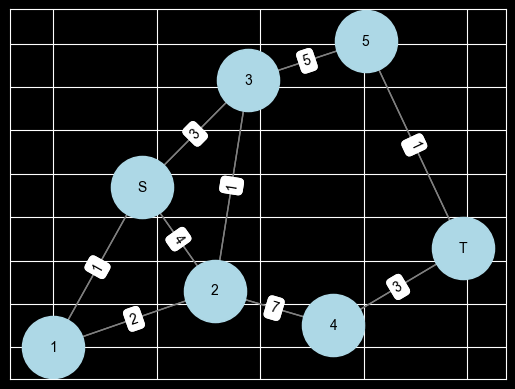

In [68]:
import networkx as nx
import matplotlib.pyplot as plt

def visualize_graph(Strassen, path=None):
    G = nx.DiGraph()
    for start, end, time in Strassen:
        G.add_edge(start, end, weight=int(time))

    pos = nx.spring_layout(G)
    edge_labels = nx.get_edge_attributes(G, 'weight')

    # Draw nodes
    nx.draw_networkx_nodes(G, pos, node_color='lightblue', node_size=2000)
    nx.draw_networkx_labels(G, pos, font_size=10)

    # Draw all edges
    nx.draw_networkx_edges(G, pos, edge_color='gray', arrows=True)

    # Highlight path if provided
    if path:
        path_edges = list(zip(path, path[1:]))
        nx.draw_networkx_edges(G, pos, edgelist=path_edges, edge_color='red', width=2, arrows=True)
        nx.draw_networkx_nodes(G, pos, nodelist=path, node_color='orange', node_size=2000)

    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels)
    plt.show()

visualize_graph(read_file("A3_Lieferkette/lieferung00.txt")[6])

## schichtengraph erstellen

### dijkstra algorithmus
- distanz zum start knoten ist 0
- für alle anderen knoten unendlich
- solange es unbesuchte knoten gibt:
    - wähle den unbesuchten knoten mit der geringsten distanz
     - für jeden nachbarn des aktuellen knotens:
        - berechne die distanz vom startknoten zum nachbarn über den aktuellen knoten
        - wenn diese distanz kleiner ist als die bisher bekannte distanz:
            - aktualisiere die distanz des nachbarn
    - markiere den aktuellen knoten als besucht

In [69]:
def dijkstra_shortest_path(Streets, source, target):
    # Extract unique nodes from the Streets list (start and end of each street)
    nodes = set()
    for start, end, weight in Streets:
        nodes.add(start)
        nodes.add(end)

    unvisited = nodes
    distances = {source: 0}
    previous = {}

    while unvisited:
        # Get the node in unvisited with the smallest distance
        current_node = min(unvisited, key=lambda node: distances.get(node, float('inf')))

        if distances.get(current_node, float('inf')) == float('inf') or current_node == target:
            break

        unvisited.remove(current_node)

        # Find neighbors of the current node
        for start, end, weight in Streets:
            if start == current_node:
                neighbor = end
                weight_val = int(weight)
                new_distance = distances[current_node] + weight_val

                if new_distance < distances.get(neighbor, float('inf')):
                    distances[neighbor] = new_distance
                    previous[neighbor] = current_node

    # Reconstruct the path
    path = []
    curr = target
    while curr in previous:
        path.insert(0, curr)
        curr = previous[curr]
    if path:
        path.insert(0, source)

    return path, distances.get(target, float("inf"))

path, distance = dijkstra_shortest_path(Streets=Strassen, source="S", target="T")
print(f"Path: {path}, Distance: {distance}")

Path: ['S', '2', 'T'], Distance: 29


### schichtengraph erstellen
- erstelle ein dict um werk id zu arbeitsschritt zuzuordnen
- gruppiere werke nach arbeitsschritt
- erstelle schichtengraph: kanten von schritt i zu schritt i+1
- für jedes werk im aktuellen schritt, finde den kürzesten weg zu allen werken im nächsten schritt

In [70]:
def create_layered_graph(Werke, Strassen):
    # Create a dictionary to map factory IDs to their stage
    factory_to_stage = {factory_id: int(stage) for factory_id, stage in Werke.items()}

    # Group factories by stage
    factories_by_stage = {}
    for factory_id, stage in factory_to_stage.items():
        stage = int(stage)
        if stage not in factories_by_stage:
            factories_by_stage[stage] = []
        factories_by_stage[stage].append(factory_id)

    # Create layered graph: edges from stage i to stage i+1
    layered_edges = []

    stages = sorted(factories_by_stage.keys())

    # Edges from S to stage 1
    for factory in factories_by_stage[stages[0]]:
        path, distance = dijkstra_shortest_path(Strassen, "S", factory)
        if distance != float('inf'):
            layered_edges.append(["S", factory, int(distance)])

    for i in range(len(stages) - 1):
        current_stage = stages[i]
        next_stage = stages[i + 1]

        current_factories = factories_by_stage[current_stage]
        next_factories = factories_by_stage[next_stage]

        # For each factory in current stage, find shortest path to all factories in next stage
        for current_factory in current_factories:
            for next_factory in next_factories:
                path, distance = dijkstra_shortest_path(Strassen, current_factory, next_factory)
                if distance != float('inf'):
                    layered_edges.append([current_factory, next_factory, int(distance)])

    # Edges from last stage to T
    for factory in factories_by_stage[stages[-1]]:
        path, distance = dijkstra_shortest_path(Strassen, factory, "T")
        if distance != float('inf'):
            layered_edges.append([factory, "T", int(distance)])

    return layered_edges

layered_graph = create_layered_graph(Werke, Strassen)
print("Schichtengraph erstellt.")

Schichtengraph erstellt.


## Dijkstra auf den Schichtengraph anwenden

In [71]:
# Wende Dijkstra auf den Schichtengraph an
path_layered, distance = dijkstra_shortest_path(layered_graph, "S", "T")
print(f"Bester Pfad durch die Werke (Schichtengraph): {path_layered}")
print(f"Gesamtzeit: {distance}")

# Rekonstruiere den vollen Pfad im Originalgraphen
full_path = []
if path_layered:
    for i in range(len(path_layered) - 1):
        segment_path, _ = dijkstra_shortest_path(Strassen, path_layered[i], path_layered[i+1])
        if i == 0:
            full_path.extend(segment_path)
        else:
            full_path.extend(segment_path[1:]) # Vermeide doppelte Knoten

print(f"Vollständiger Pfad im Straßennetz: {full_path}")

if int(distance) <= int(T):
    print("Die Lieferung ist innerhalb der Zeitfrist möglich.")
else:
    print("Die Lieferung ist NICHT innerhalb der Zeitfrist möglich.")


Bester Pfad durch die Werke (Schichtengraph): ['S', '11', '45', '76', '77', '112', '72', '167', '175', '200', '185', '113', '186', '100', '114', '115', '275', '276', '42', '255', '302', '225', '201', '57', '19', '21', '91', '79', '260', '193', '269', '86', '73', '301', '155', '329', '259', '245', '316', '356', '195', '64', '246', '349', '219', '274', '143', '215', '224', '273', '336', 'T']
Gesamtzeit: 875
Vollständiger Pfad im Straßennetz: ['S', '1', '133', '159', '12', '11', '12', '45', '47', '331', '79', '76', '77', '109', '112', '114', '143', '72', '116', '167', '169', '175', '169', '64', '251', '203', '200', '113', '185', '113', '185', '186', '169', '64', '251', '100', '195', '254', '143', '114', '112', '115', '225', '302', '79', '76', '78', '187', '277', '275', '276', '42', '274', '201', '255', '201', '115', '225', '302', '225', '115', '201', '115', '112', '114', '57', '322', '19', '15', '21', '12', '160', '206', '207', '91', '172', '173', '302', '79', '302', '173', '224', '96', '

## Besten Pfad visualisieren

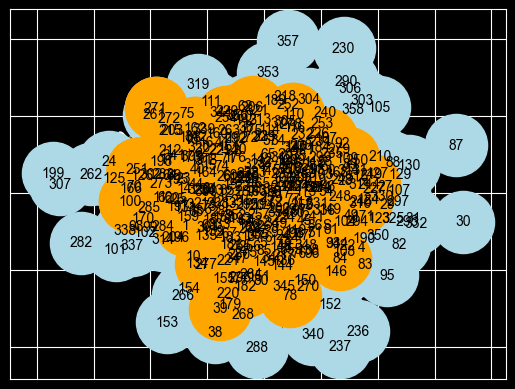

In [72]:
visualize_graph(Strassen, full_path)

## Streik-Szenarien für alle Werke auf dem optimalen Pfad testen

In [73]:
print("Streik Scenarios testen")
print(f"Optimaler Pfad ohne Streik: {path_layered}")
print(f"Optimale Zeit ohne Streik: {distance}")
print()

# Für jedes Werk auf dem optimalen Pfad (außer S und T) einen Streik simulieren
factories_to_test = [f for f in path_layered if f != "S" and f != "T"]

all_feasible = True
contingency_plans = {}

for strike_factory in factories_to_test:
    print(f"Szenario: Werk {strike_factory} ist bestreikt")

    # Finde die Position des streikenden Werks im optimalen Pfad
    strike_index = path_layered.index(strike_factory)

    # Behalte den optimalen Pfad bis zum streikenden Werk (inklusive)
    path_up_to_strike = path_layered[:strike_index + 1]

    # Berechne die Zeit bis zum streikenden Werk (inklusive)
    time_up_to_strike = 0
    for i in range(len(path_up_to_strike) - 1):
        for edge in layered_graph:
            if edge[0] == path_up_to_strike[i] and edge[1] == path_up_to_strike[i + 1]:
                time_up_to_strike += edge[2]
                break

    # Erstelle modifizierten Schichtengraph:
    # Das streikende Werk kann die Arbeit nicht selbst durchführen, aber es kann eine Alternative im gleichen Schritt delegieren
    factory_to_stage = {factory_id: int(stage) for factory_id, stage in Werke.items()}
    strike_stage = factory_to_stage[strike_factory]

    # Finde alle Factories im gleichen Schritt
    factories_in_same_stage = [fid for fid, stage in factory_to_stage.items() if stage == strike_stage and fid != strike_factory]

    filtered_layered_graph = []
    for edge in layered_graph:
        source, target, weight = edge[0], edge[1], edge[2]

        # Wenn eine Kante zum streikenden Werk führt, überspringe sie
        if target == strike_factory:
            continue

        # Wenn eine Kante vom streikenden Werk kommt ur zu anderen Werken im gleichen Schritt erlauben (Delegation)
        if source == strike_factory:
            if target in factories_in_same_stage:
                filtered_layered_graph.append(edge)
        else:
            # Alle anderen Kanten erlauben
            filtered_layered_graph.append(edge)

    # Füge Kanten hinzu, um vom streikenden Werk zu alternativen Werken im gleichen Schritt zu gehen
    for alt_factory in factories_in_same_stage:
        path, distance = dijkstra_shortest_path(Strassen, strike_factory, alt_factory)
        if distance != float('inf'):
            filtered_layered_graph.append([strike_factory, alt_factory, int(distance)])

    # Finde den besten Weg vom streikenden Werk zum Ziel
    path_from_strike, distance_from_strike = dijkstra_shortest_path(filtered_layered_graph, strike_factory, "T")

    # Kombiniere die Pfade
    if path_from_strike and distance_from_strike != float('inf'):
        # Vermeide Dopplung des Streik-Knotens
        path_with_strike = path_up_to_strike + path_from_strike[1:]
        distance_with_strike = time_up_to_strike + distance_from_strike
    else:
        path_with_strike = []
        distance_with_strike = float('inf')

    print(f"Notfall-Pfad: {path_with_strike}")
    print(f"Zeit mit Streik: {distance_with_strike}")

    # Prüfe ob innerhalb Zeitfrist
    if distance_with_strike != float('inf') and int(distance_with_strike) <= int(T):
        print(f"Lieferung möglich innerhalb Zeitfrist ({distance_with_strike} ≤ {T})")
    else:
        if distance_with_strike == float('inf'):
            print(f"Lieferung nicht möglich (kein alternativer Weg gefunden)")
        else:
            print(f"Lieferung nicht möglich ({distance_with_strike} > {T})")
        all_feasible = False

    # Rekonstruiere vollen Pfad im Originalgraph
    full_path_strike = []
    if path_with_strike and distance_with_strike != float('inf'):
        for i in range(len(path_with_strike) - 1):
            segment_path, _ = dijkstra_shortest_path(Strassen, path_with_strike[i], path_with_strike[i+1])
            if i == 0:
                full_path_strike.extend(segment_path)
            else:
                full_path_strike.extend(segment_path[1:])

    contingency_plans[strike_factory] = {
        'path_layered': path_with_strike,
        'path_full': full_path_strike,
        'distance': distance_with_strike,
        'feasible': distance_with_strike != float('inf') and int(distance_with_strike) <= int(T)
    }

    print(f"Vollständiger Pfad: {full_path_strike}")
    print()


print("\nZusammenfassung der Streik-Szenarien:")
print("=" * 50)

possible_strikes = [factory for factory, plan in contingency_plans.items() if plan['feasible']]
impossible_strikes = [factory for factory, plan in contingency_plans.items() if not plan['feasible']]

if possible_strikes:
    print(f"Lieferung moglich bei Streik von: {', '.join(possible_strikes)}")
else:
    print("Keine Werke, bei deren Streik die Lieferung moglich ist.")

if impossible_strikes:
    print(f"Lieferung nicht moglich bei Streik von: {', '.join(impossible_strikes)}")
else:
    print("Alle Werke: Die Lieferung bleibt bei Streik moglich.")





Streik Scenarios testen
Optimaler Pfad ohne Streik: ['S', '11', '45', '76', '77', '112', '72', '167', '175', '200', '185', '113', '186', '100', '114', '115', '275', '276', '42', '255', '302', '225', '201', '57', '19', '21', '91', '79', '260', '193', '269', '86', '73', '301', '155', '329', '259', '245', '316', '356', '195', '64', '246', '349', '219', '274', '143', '215', '224', '273', '336', 'T']
Optimale Zeit ohne Streik: 875

Szenario: Werk 11 ist bestreikt
Notfall-Pfad: ['S', '11', '15', '45', '76', '77', '112', '72', '167', '175', '200', '185', '113', '186', '100', '114', '115', '275', '276', '42', '255', '302', '225', '201', '57', '19', '21', '91', '79', '260', '193', '269', '86', '73', '301', '155', '329', '259', '245', '316', '356', '195', '64', '246', '349', '219', '274', '143', '215', '224', '273', '336', 'T']
Zeit mit Streik: 901
Lieferung möglich innerhalb Zeitfrist (901 ≤ 930)
Vollständiger Pfad: ['S', '1', '133', '159', '12', '11', '12', '21', '15', '21', '12', '45', '47', 